# Grouping currencies with DTW

We want to find currencies whose historical FX behavior is similar enough to make them candidates for **pooled training**. Each currency is one observation in clustering; each currency-month remains a separate row when we build the training batches.

We use monthly BIS FX log returns from **January 2011 to December 2019**. This common window follows the configured peg exclusions and leaves later observations available for forecasting evaluation. BIS harmonization makes measurements comparable; it does not establish that currencies share a forecasting relationship.

Install the optional dependency once in the notebook's environment: `python -m pip install -e ".[clustering]"`.

The code below calculates and plots the results. The checks, model choices, and interpretation are written in Markdown.

In [29]:
!!python -m pip install -e ".[clustering]"

['Obtaining file:///Users/alexandresepulvedadedietrich/Documents/School/Columbia/Fall_2026/Deep_Learning/emerging-market-fx-neural-network/notebooks',
 '',
 '\x1b[\x1b\x1bnotice\x1b\x1b[1;39;49m]\x1b\x1b A new release of pip is available: \x1b\x1b26.1.1\x1b\x1b -> \x1b\x1b26.2.2\x1b',
 '\x1b[\x1b\x1bnotice\x1b\x1b[1;39;49m]\x1b\x1b To update, run: \x1b\x1bpip install --upgrade pip\x1b',
 "\x1bERROR: file:///Users/alexandresepulvedadedietrich/Documents/School/Columbia/Fall_2026/Deep_Learning/emerging-market-fx-neural-network/notebooks does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.\x1b\x1b",
 '\x1b']

In [3]:
from pathlib import Path
from itertools import combinations
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.manifold import MDS
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from tslearn.clustering import TimeSeriesKMeans
from tslearn.metrics import cdist_dtw

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "reports" / "clustering"
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Sample and returns

Use the exact FX series IDs in `research_sample.json`. Mask pre-launch history and the documented peg periods **before** calculating returns. Returns are `100 × change in log(FX)`, so a positive return means depreciation against USD.

Missing or nonpositive FX stays missing. Differencing breaks the return history on both sides of a missing level. For clustering we retain currencies with a complete, nonconstant history over the same calendar; the coverage table makes exclusions visible.

In [4]:
START, END = "2011-01", "2019-12"
RADIUS = 2
SEEDS = (7, 42, 99)
K_VALUES = range(1, 7)
DTW = {"global_constraint": "sakoe_chiba", "sakoe_chiba_radius": RADIUS}
FIT = dict(metric="dtw", metric_params=DTW, n_init=3, max_iter=20,
           max_iter_barycenter=10, n_jobs=1)

cfg = json.loads((ROOT / "config/research_sample.json").read_text())
obs = pd.read_parquet(ROOT / "data/ingested/observations.parquet")
metadata = pd.DataFrame(cfg["currencies"]).set_index("currency")

In [38]:
# FIT

In [5]:
sources = {c["source_series"]["fx"]: c["currency"] for c in cfg["currencies"]}
rows = obs.loc[obs.dataset.eq("WS_XRU") & obs.frequency.eq("M")
               & obs.series_id.isin(sources)].copy()
rows["currency"] = rows.series_id.map(sources)
fx = rows.pivot(index="period", columns="currency", values="value")
fx.index = pd.PeriodIndex(fx.index, freq="M")
fx = fx.reindex(index=pd.period_range(**cfg["monthly_window"], freq="M"),
                columns=metadata.index).astype(float)
fx = fx.where(np.isfinite(fx) & fx.gt(0))

for c in cfg["currencies"]:
    fx.loc[fx.index < pd.Period(c["first_eligible_month"], "M"), c["currency"]] = np.nan
area_to_currency = {c["area"]: c["currency"] for c in cfg["currencies"]}
for interval in cfg["excluded_month_intervals"]:
    fx.loc[interval["start"]:interval["end"], area_to_currency[interval["area"]]] = np.nan

In [6]:
returns = 100 * np.log(fx).diff()
window = returns.loc[START:END]
coverage = pd.DataFrame({"observed_months": window.notna().sum(),
                         "missing_months": window.isna().sum()})
coverage["included"] = window.notna().all() & window.std(ddof=0).gt(1e-12)
window = window.loc[:, coverage.index[coverage.included]]
currencies = window.columns.tolist()
display(coverage)

,observed_months,missing_months,included
currency,,,
DZD,108,0,True
ARS,108,0,True
AUD,108,0,True
BAM,108,0,True
BRL,108,0,True
CAD,108,0,True
CLP,108,0,True
CNY,108,0,True
TWD,108,0,True


<Axes: >

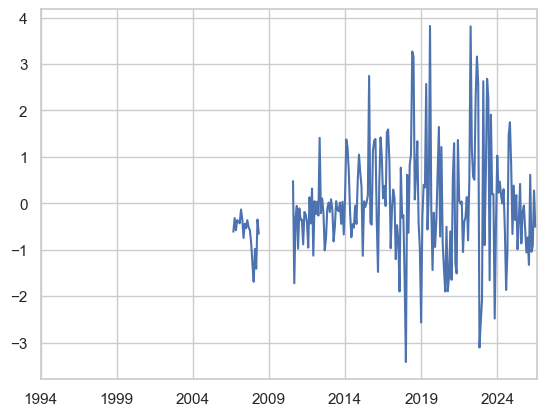

In [35]:
returns["CNY"].plot()

**Coverage check for the saved run:** all **39 currencies** have **108 monthly returns** in this window. No FX values were filled. If the dates change, review the coverage table before interpreting the clusters.

## 2. DTW clustering

Standardize each currency's returns using its own mean and standard deviation within this historical window. This groups **patterns of movement**, rather than differences in average depreciation or volatility.

DTW can match observations at most **two months apart**. We fit K=1–6 with three seeds and three initializations per seed. K=1 provides the starting point for inertia; silhouette is defined here only for K≥2. Silhouette uses the same constrained DTW distance matrix as clustering.

In [7]:
standardized = (window - window.mean()) / window.std(ddof=0)
X = standardized.T.to_numpy()[:, :, None]
D = cdist_dtw(X, **DTW, n_jobs=1)

In [8]:
models, rows = {}, []
for k in K_VALUES:
    for seed in SEEDS:
        model = TimeSeriesKMeans(n_clusters=k, random_state=seed, **FIT).fit(X)
        models[k, seed] = model
        score = silhouette_score(D, model.labels_, metric="precomputed") if k > 1 else np.nan
        rows.append({"k": k, "seed": seed, "silhouette": score,
                     "inertia": model.inertia_,
                     "smallest_cluster": np.bincount(model.labels_, minlength=k).min()})
results = pd.DataFrame(rows)
summary = results.groupby("k").agg(
    silhouette=("silhouette", "median"), low=("silhouette", "min"),
    high=("silhouette", "max"), inertia=("inertia", "median"),
    smallest_cluster=("smallest_cluster", "min"))
display(summary.round(3))

,silhouette,low,high,inertia,smallest_cluster
k,,,,,
1,NaN,NaN,NaN,39.401,39
2,0.122,0.109,0.236,36.217,3
3,0.125,0.095,0.128,31.540,3
4,0.117,0.078,0.118,30.624,2
5,0.115,0.066,0.120,28.048,1
6,0.116,0.104,0.125,24.931,1


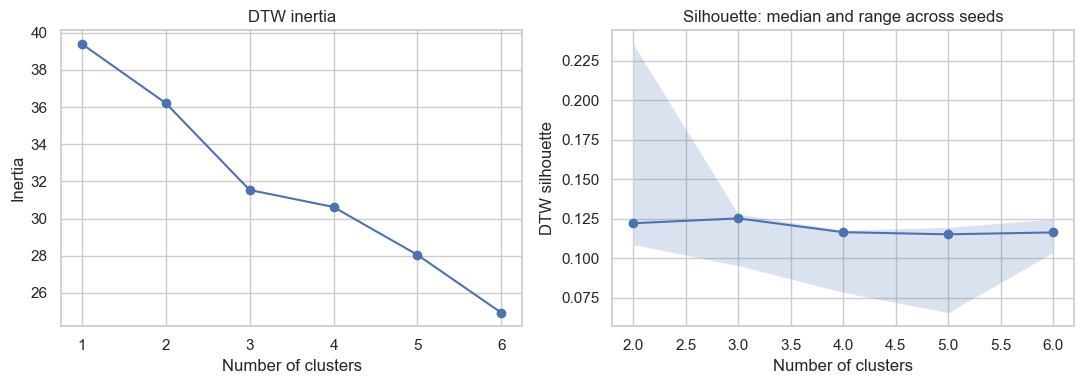

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(summary.index, summary.inertia, "o-")
axes[0].set(title="DTW inertia", xlabel="Number of clusters", ylabel="Inertia")
s = summary.loc[2:]
axes[1].plot(s.index, s.silhouette, "o-")
axes[1].fill_between(s.index, s.low, s.high, alpha=.2)
axes[1].set(title="Silhouette: median and range across seeds",
            xlabel="Number of clusters", ylabel="DTW silhouette")
fig.tight_layout()
fig.savefig(OUT / "cluster_selection.png", dpi=180)
plt.show()

## 3. Choosing K

**Use K=3 for this exploratory grouping.** In the saved run, median silhouette is about **0.125** at K=3 versus **0.122** at K=2. The inertia curve bends around three groups. Both solutions keep at least three currencies per cluster across seeds; higher K introduces smaller groups.

This is a modest preference, not strong evidence for three distinct populations. The seed ranges are wide and the silhouette values are low. Choose K by reading the plots and considering the intended training batches, rather than combining the diagnostics into an automatic score.

For the chosen K, take the run with the lowest inertia. Representative currencies are **medoids**: observed histories closest on average to other members of their group. Number the groups alphabetically by representative so their labels are easy to follow.

In [10]:
K = 3
best = results.loc[results.k.eq(K)].sort_values(["inertia", "seed"]).iloc[0]
model = models[K, int(best.seed)]
labels = model.labels_

representatives = {}
for label in np.unique(labels):
    idx = np.flatnonzero(labels == label)
    representatives[label] = currencies[idx[D[np.ix_(idx, idx)].sum(axis=1).argmin()]]
numbering = {label: i + 1 for i, label in enumerate(sorted(representatives, key=representatives.get))}

In [11]:
members = pd.DataFrame(index=pd.Index(currencies, name="currency"))
members["economy"] = metadata.loc[currencies, "economy"]
members["pool_id"] = [numbering[label] for label in labels]
members["representative_currency"] = [representatives[label] for label in labels]
members["silhouette"] = silhouette_samples(D, labels, metric="precomputed")
members["mean_monthly_depreciation_pct"] = window.mean()
members["monthly_volatility_pct"] = window.std(ddof=0)

pool_summary = members.groupby("pool_id").agg(
    currencies=("economy", "size"), representative=("representative_currency", "first"),
    silhouette_mean=("silhouette", "mean"))
pool_summary["members"] = members.reset_index().groupby("pool_id").currency.agg(
    lambda names: ", ".join(sorted(names)))
display(pool_summary.round(3))

,currencies,representative,silhouette_mean,members
pool_id,,,,
1,22,AUD,0.010,"AUD, BRL, CAD, CLP, COP, IDR, ILS, INR, ISK, J..."
2,3,CNY,-0.010,"ARS, CNY, GBP"
3,14,EUR,0.343,"BAM, CHF, CZK, DKK, DZD, EUR, HUF, MAD, MKD, N..."


**Reading the groups:** the saved run has **22, 3, and 14 currencies**. The EUR-centered group is the clearest, with mean silhouette about **0.343**. The other two groups have mean silhouette near zero. In particular, putting ARS, CNY, and GBP together should not be interpreted as an established economic relationship.

## 4. Plot the clusters

MDS projects the DTW distances into two dimensions for viewing. Colors show the existing cluster assignments; the projection does not create new clusters. The axes have no direct economic meaning and distances are approximate. The static map labels representative currencies; the interactive map lets you hover over every currency.

In [37]:
coordinates = MDS(n_components=2, dissimilarity="precomputed", n_init=8,
                  max_iter=1000, eps=1e-6, random_state=42,
                  normalized_stress=False).fit_transform(D)
cluster_map = members.join(pd.DataFrame(coordinates, index=currencies,
                                        columns=["mds_1", "mds_2"]))
colors = dict(zip(sorted(members.pool_id.unique()), sns.color_palette("tab10", K).as_hex()))

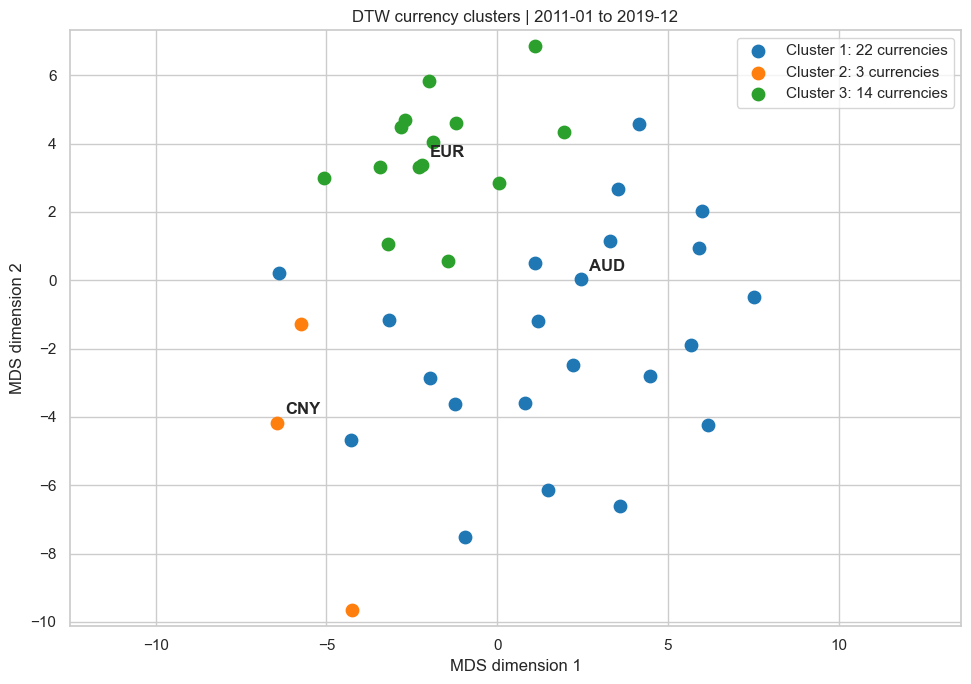

In [13]:
fig, ax = plt.subplots(figsize=(10, 7))
for pool_id, group in cluster_map.groupby("pool_id"):
    ax.scatter(group.mds_1, group.mds_2, s=80, color=colors[pool_id],
               label=f"Cluster {pool_id}: {len(group)} currencies")
    representative = group.representative_currency.iloc[0]
    point = group.loc[representative]
    ax.annotate(representative, (point.mds_1, point.mds_2), xytext=(6, 6),
                textcoords="offset points", fontweight="bold")
ax.set(title=f"DTW currency clusters | {START} to {END}",
       xlabel="MDS dimension 1", ylabel="MDS dimension 2")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "currency_clusters.png", dpi=180)
fig.savefig(OUT / "currency_clusters.svg")
plt.show()

In [14]:
interactive = cluster_map.reset_index()
interactive["cluster"] = "Cluster " + interactive.pool_id.astype(str)
color_map = {f"Cluster {k}": color for k, color in colors.items()}
chart = px.scatter(interactive, x="mds_1", y="mds_2", color="cluster",
                   hover_name="currency", hover_data=["economy", "silhouette"],
                   color_discrete_map=color_map, title="DTW currency clusters")
chart.update_yaxes(scaleanchor="x", scaleratio=1)
chart.write_html(OUT / "currency_clusters.html", include_plotlyjs=True)

The heatmap below retains the full DTW distances. Read it alongside the MDS view because the projection loses information. The time-series plots show standardized returns at their actual calendar dates, with each representative highlighted.

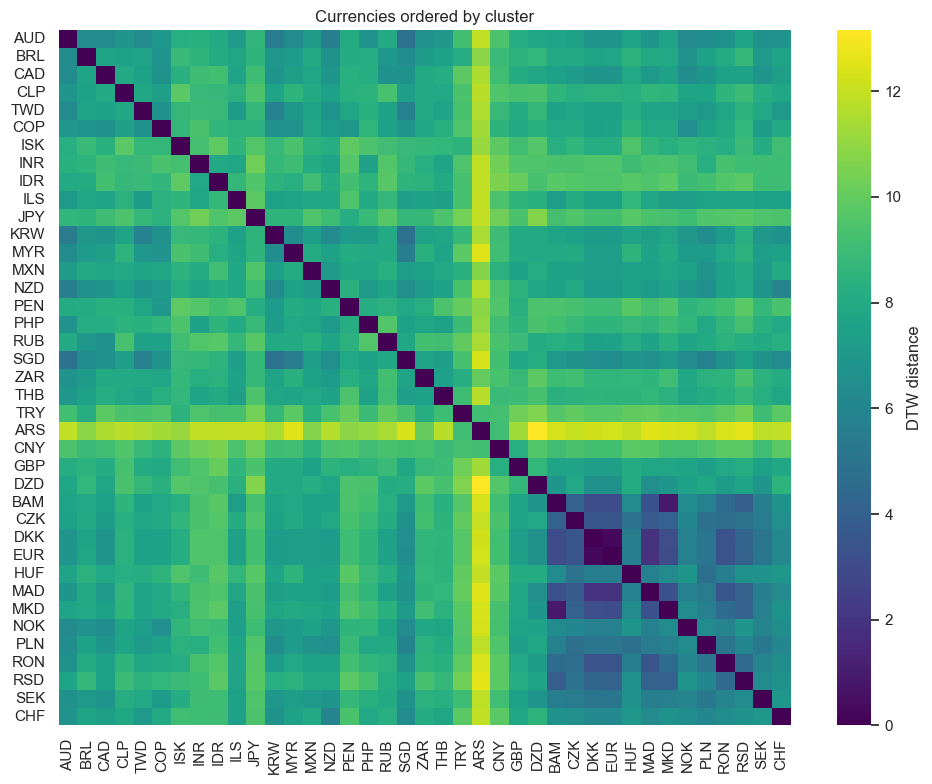

In [15]:
order = members.sort_values("pool_id", kind="stable").index
positions = [currencies.index(currency) for currency in order]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(D[np.ix_(positions, positions)], xticklabels=order, yticklabels=order,
            cmap="viridis", ax=ax, cbar_kws={"label": "DTW distance"})
ax.set_title("Currencies ordered by cluster")
fig.tight_layout()
plt.show()

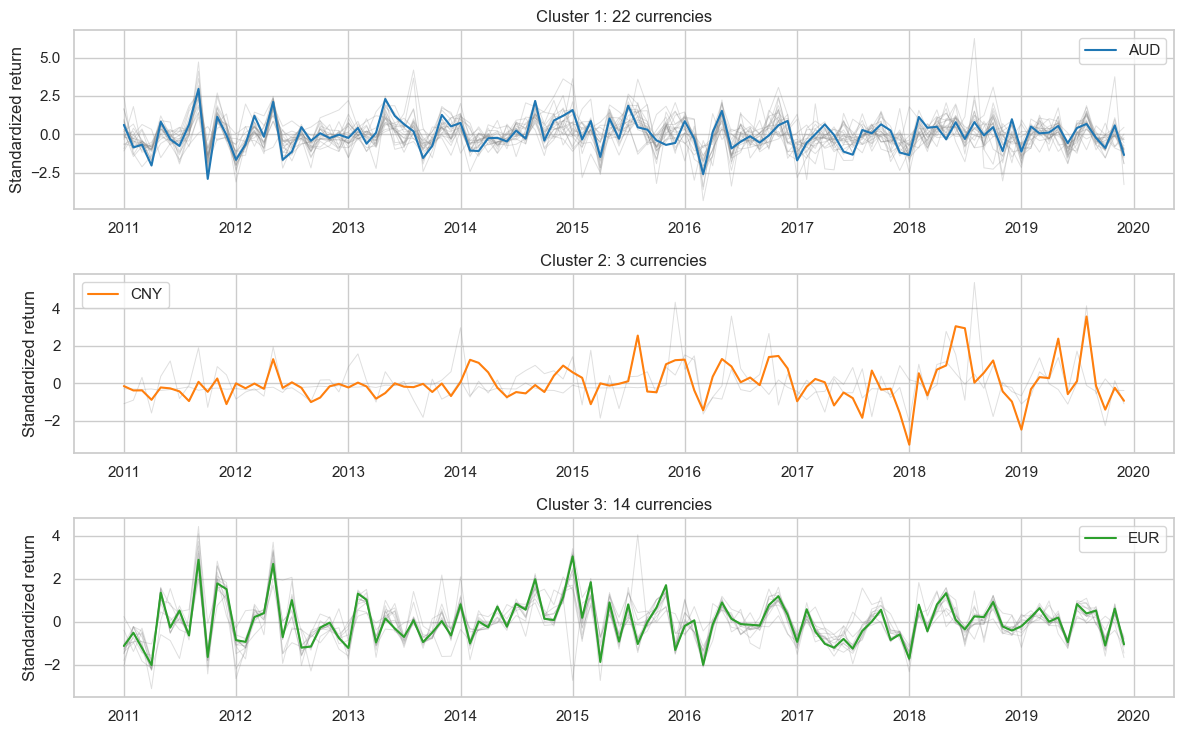

In [16]:
fig, axes = plt.subplots(K, 1, figsize=(12, 2.5 * K), squeeze=False)
for ax, (pool_id, group) in zip(axes[:, 0], members.groupby("pool_id")):
    dates = window.index.to_timestamp()
    ax.plot(dates, standardized[group.index], color="gray", alpha=.25, linewidth=.7)
    representative = group.representative_currency.iloc[0]
    ax.plot(dates, standardized[representative], color=colors[pool_id], label=representative)
    ax.set(title=f"Cluster {pool_id}: {len(group)} currencies", ylabel="Standardized return")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "currency_cluster_histories.png", dpi=180)
plt.show()

## 5. Sensitivity checks

**Question:** would we get similar groups with different seeds, shorter historical windows, or another distance definition?

Adjusted Rand index (ARI) compares memberships while ignoring the numerical group labels; 1 means identical memberships. The following cells calculate the comparisons. The interpretation belongs here: seed agreement in the saved run is weak, while the two overlapping historical windows give ARI around **0.69** and **0.66**. These overlapping windows are sensitivities, not independent tests.

The Euclidean control removes warping. The magnitude sensitivity keeps differences in average depreciation and volatility by applying one common scale. Large membership changes show that grouping depends on how similarity is defined; they do not establish which grouping forecasts better.

In [17]:
seed_agreement = [adjusted_rand_score(models[K, a].labels_, models[K, b].labels_)
                  for a, b in combinations(SEEDS, 2)]
display(pd.DataFrame({"comparison": ["Mean ARI across seeds"],
                      "ARI": [np.mean(seed_agreement)]}).round(3))

stability = []
for start, end in [(START, "2017-12"), ("2013-01", END)]:
    sub = window.loc[start:end]
    Z = ((sub - sub.mean()) / sub.std(ddof=0)).T.to_numpy()[:, :, None]
    fitted = TimeSeriesKMeans(n_clusters=K, random_state=42, **FIT).fit(Z)
    stability.append({"start": start, "end": end,
                      "ARI": adjusted_rand_score(labels, fitted.labels_)})
window_stability = pd.DataFrame(stability)
display(window_stability.round(3))

,comparison,ARI
0,Mean ARI across seeds,0.306


,start,end,ARI
0,2011-01,2017-12,0.692
1,2013-01,2019-12,0.655


In [18]:
euclidean = KMeans(n_clusters=K, init="random", n_init=10, random_state=42).fit(X[:, :, 0])
magnitude = (window / window.to_numpy().std()).T.to_numpy()[:, :, None]
magnitude_model = TimeSeriesKMeans(n_clusters=K, random_state=42, **FIT).fit(magnitude)
sensitivity = pd.DataFrame({
    "comparison": ["Euclidean, standardized returns", "DTW, magnitude retained"],
    "ARI_vs_selected": [adjusted_rand_score(labels, euclidean.labels_),
                        adjusted_rand_score(labels, magnitude_model.labels_)]})
display(sensitivity.round(3))

,comparison,ARI_vs_selected
0,"Euclidean, standardized returns",0.743
1,"DTW, magnitude retained",0.597


## 6. Put currencies into training batches

Keep one row per **currency, forecast origin, and horizon**. The common FX-only predictors are the current return, its first two lags, the last three returns' mean, and twelve-month volatility. Pooling combines rows; it does not average currencies or remove their identities.

**Target check:** targets are original cumulative log returns over 1, 3, or 12 months. Every FX level from origin through target endpoint must be observed and eligible. Truncating the source history at December 2019 ensures every retained training target has already realised by that cutoff. Rolling predictors require complete consecutive returns, so histories restart across gaps.

The batches below are for fitting models used **after December 2019**. Group labels learned from this window must not be backfilled into the original January 2010 evaluation. Adding macro predictors later requires the same feature definitions, availability lags, and missing-data treatment for all currencies.

In [19]:
history = fx.loc[:END, currencies]
r = 100 * np.log(history).diff()
features = {"fx_return_t": r, "fx_return_lag1": r.shift(1),
            "fx_return_lag2": r.shift(2),
            "fx_return_mean3": r.rolling(3).mean(),
            "fx_volatility12": r.rolling(12).std(ddof=0)}

In [20]:
parts = []
for h in (1, 3, 12):
    target = 100 * (np.log(history).shift(-h) - np.log(history))
    complete = history.notna().rolling(h + 1).sum().shift(-h).eq(h + 1)
    target = target.where(complete)
    for currency, pool_id in members.pool_id.items():
        batch = pd.DataFrame({name: values[currency] for name, values in features.items()})
        batch["target_log_return_pct"] = target[currency]
        batch = batch.loc[START:].dropna().copy()
        batch["currency"], batch["pool_id"], batch["horizon"] = currency, pool_id, h
        batch["target_end"] = batch.index + h
        parts.append(batch.rename_axis("origin").reset_index())
training_panel = pd.concat(parts, ignore_index=True)
training_batches = {key: rows.reset_index(drop=True)
                    for key, rows in training_panel.groupby(["horizon", "pool_id"])}

In [21]:
batch_sizes = training_panel.groupby(["horizon", "pool_id"]).agg(
    rows=("currency", "size"), currencies=("currency", "nunique"),
    first_origin=("origin", "min"), last_origin=("origin", "max"),
    latest_target_end=("target_end", "max"))
display(batch_sizes)
display(training_batches[3, 1].head())

rows  currencies first_origin last_origin latest_target_end
horizon pool_id                                                             
1       1        2354          22      2011-01     2019-11           2019-12
        2         315           3      2011-01     2019-11           2019-12
        3        1498          14      2011-01     2019-11           2019-12
3       1        2310          22      2011-01     2019-09           2019-12
        2         309           3      2011-01     2019-09           2019-12
        3        1470          14      2011-01     2019-09           2019-12
12      1        2112          22      2011-01     2018-12           2019-12
        2         282           3      2011-01     2018-12           2019-12
        3        1344          14      2011-01     2018-12           2019-12

,origin,fx_return_t,fx_return_lag1,fx_return_lag2,fx_return_mean3,fx_volatility12,target_log_return_pct,currency,pool_id,horizon,target_end
0,2011-01,2.223127,-6.196512,1.932934,-0.680150,4.657264,-9.672116,AUD,1,3,2011-04
1,2011-02,-2.215906,2.223127,-6.196512,-2.063097,4.655365,-4.621323,AUD,1,3,2011-05
2,2011-03,-1.672856,-2.215906,2.223127,-0.555211,4.636017,-3.560934,AUD,1,3,2011-06
3,2011-04,-5.783355,-1.672856,-2.215906,-3.224039,4.817939,0.287799,AUD,1,3,2011-07
4,2011-05,2.834888,-5.783355,-1.672856,-1.540441,3.727348,-0.265917,AUD,1,3,2011-08


**Batch check for the saved run:** **11,994 rows** across the three horizons; all target endpoints are December 2019 or earlier. The batch-size table shows the last origin and endpoint for each group. Separate horizons when fitting a model. Treat cluster and currency IDs as categorical identifiers.

## 7. Save the results

Memberships, diagnostics, plots, and the pooled training table are saved under `reports/clustering/`. The settings file records the historical window and selected fit. All calculations are visible above; this notebook does not depend on separate clustering helper or test modules.

In [22]:
coverage.to_csv(OUT / "coverage.csv")
results.to_csv(OUT / "grid_scores.csv", index=False)
summary.to_csv(OUT / "model_selection.csv")
members.to_csv(OUT / "memberships.csv")
pool_summary.to_csv(OUT / "pool_summary.csv")
window_stability.to_csv(OUT / "window_stability.csv", index=False)
cluster_map.to_csv(OUT / "cluster_map.csv")
batch_sizes.to_csv(OUT / "batch_sizes.csv")
training_panel.to_parquet(OUT / "pooled_training.parquet", index=False)
settings = {"fit_start": START, "fit_end": END, "representation": "shape",
            "selected_k": K, "selected_seed": int(best.seed), "dtw_parameters": DTW,
            "training_rows": len(training_panel), "currencies": currencies}
(OUT / "manifest.json").write_text(json.dumps(settings, indent=2))

695

## Conclusion

The EUR-centered group is the most coherent candidate pool. The other groups are weakly separated, so there is not yet a strong basis for fitting separate networks to all three groups. A useful next experiment is to compare a global model with the same model plus cluster information on later validation dates.

The checks here cover data eligibility, clustering sensitivity, and target timing. **Forecast improvement has not been tested.** With low silhouette, unstable memberships, and shared USD shocks, pooled row counts should not be interpreted as independent observations.

The numerical descriptions in Markdown refer to the saved default run. Update them if the dates or model settings change.

References: [DTW constraints](https://tslearn.readthedocs.io/en/stable/user_guide/dtw.html), [DTW clustering](https://tslearn.readthedocs.io/en/stable/user_guide/clustering.html), [silhouette](https://tslearn.readthedocs.io/en/stable/gen_modules/clustering/tslearn.clustering.silhouette_score.html).